# Projet 08 — SQL Avancé : Analyse des Performances avec AdventureWorks

**Auteur :** Steven Barde  
**Date :** Octobre 2026  
**Objectif :** Analyser les performances commerciales (ventes, produits, régions, clients) via SQL avancé sur une base AdventureWorks recréée en SQLite.

**Compétences :** Jointures complexes · Window Functions · Sous-requêtes · Vues SQL · Agrégations

## 1. Imports et Configuration

In [1]:
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from datetime import datetime, timedelta
import random
import warnings
warnings.filterwarnings('ignore')

# Style global
plt.rcParams['figure.facecolor'] = '#0d1117'
plt.rcParams['axes.facecolor'] = '#161b22'
plt.rcParams['text.color'] = '#e6edf3'
plt.rcParams['axes.labelcolor'] = '#8b949e'
plt.rcParams['xtick.color'] = '#8b949e'
plt.rcParams['ytick.color'] = '#8b949e'
plt.rcParams['axes.edgecolor'] = '#30363d'
plt.rcParams['grid.color'] = '#21262d'
plt.rcParams['font.family'] = 'DejaVu Sans'

DB_PATH = '../dataset/adventureworks.db'
print('✅ Imports OK')

✅ Imports OK


## 2. Création de la Base de Données AdventureWorks (SQLite)

In [2]:
import os
os.makedirs('../dataset', exist_ok=True)

conn = sqlite3.connect(DB_PATH)
cur = conn.cursor()

# --- Tables ---
cur.executescript('''
DROP TABLE IF EXISTS SalesOrderDetail;
DROP TABLE IF EXISTS SalesOrderHeader;
DROP TABLE IF EXISTS Customer;
DROP TABLE IF EXISTS Product;
DROP TABLE IF EXISTS ProductCategory;
DROP TABLE IF EXISTS ProductSubcategory;
DROP TABLE IF EXISTS SalesPerson;
DROP TABLE IF EXISTS Region;
DROP TABLE IF EXISTS SalesReturn;

CREATE TABLE Region (
    RegionID INTEGER PRIMARY KEY,
    RegionName TEXT,
    Country TEXT
);

CREATE TABLE ProductCategory (
    CategoryID INTEGER PRIMARY KEY,
    CategoryName TEXT
);

CREATE TABLE ProductSubcategory (
    SubcategoryID INTEGER PRIMARY KEY,
    SubcategoryName TEXT,
    CategoryID INTEGER,
    FOREIGN KEY (CategoryID) REFERENCES ProductCategory(CategoryID)
);

CREATE TABLE Product (
    ProductID INTEGER PRIMARY KEY,
    ProductName TEXT,
    SubcategoryID INTEGER,
    ListPrice REAL,
    StandardCost REAL,
    FOREIGN KEY (SubcategoryID) REFERENCES ProductSubcategory(SubcategoryID)
);

CREATE TABLE SalesPerson (
    SalesPersonID INTEGER PRIMARY KEY,
    FirstName TEXT,
    LastName TEXT,
    RegionID INTEGER,
    FOREIGN KEY (RegionID) REFERENCES Region(RegionID)
);

CREATE TABLE Customer (
    CustomerID INTEGER PRIMARY KEY,
    FirstName TEXT,
    LastName TEXT,
    CustomerType TEXT,
    RegionID INTEGER,
    FOREIGN KEY (RegionID) REFERENCES Region(RegionID)
);

CREATE TABLE SalesOrderHeader (
    SalesOrderID INTEGER PRIMARY KEY,
    CustomerID INTEGER,
    SalesPersonID INTEGER,
    OrderDate TEXT,
    Channel TEXT,
    FOREIGN KEY (CustomerID) REFERENCES Customer(CustomerID),
    FOREIGN KEY (SalesPersonID) REFERENCES SalesPerson(SalesPersonID)
);

CREATE TABLE SalesOrderDetail (
    DetailID INTEGER PRIMARY KEY,
    SalesOrderID INTEGER,
    ProductID INTEGER,
    OrderQty INTEGER,
    UnitPrice REAL,
    LineTotal REAL,
    FOREIGN KEY (SalesOrderID) REFERENCES SalesOrderHeader(SalesOrderID),
    FOREIGN KEY (ProductID) REFERENCES Product(ProductID)
);

CREATE TABLE SalesReturn (
    ReturnID INTEGER PRIMARY KEY,
    SalesOrderID INTEGER,
    ProductID INTEGER,
    ReturnQty INTEGER,
    ReturnDate TEXT,
    FOREIGN KEY (ProductID) REFERENCES Product(ProductID)
);
''')
conn.commit()
print('✅ Tables créées')

✅ Tables créées


In [3]:
random.seed(42)
np.random.seed(42)

# Régions
regions = [
    (1,'Northwest','USA'),(2,'Northeast','USA'),(3,'Southwest','USA'),
    (4,'Southeast','USA'),(5,'Central','USA'),(6,'Canada','Canada'),
    (7,'France','France'),(8,'Germany','Germany'),(9,'Australia','Australia')
]
cur.executemany('INSERT INTO Region VALUES (?,?,?)', regions)

# Catégories
categories = [(1,'Bikes'),(2,'Components'),(3,'Clothing'),(4,'Accessories')]
cur.executemany('INSERT INTO ProductCategory VALUES (?,?)', categories)

# Sous-catégories
subcats = [
    (1,'Mountain Bikes',1),(2,'Road Bikes',1),(3,'Touring Bikes',1),
    (4,'Handlebars',2),(5,'Brakes',2),(6,'Wheels',2),
    (7,'Jerseys',3),(8,'Shorts',3),(9,'Gloves',3),
    (10,'Helmets',4),(11,'Bottles',4),(12,'Pumps',4)
]
cur.executemany('INSERT INTO ProductSubcategory VALUES (?,?,?)', subcats)

# Produits (30 produits)
product_names = [
    ('Mountain-200 Black 38',1,2699.99,1912.15), ('Mountain-200 Silver 42',1,2319.99,1555.00),
    ('Road-150 Red 62',2,3578.27,2171.29), ('Road-250 Black 44',2,2443.35,1554.95),
    ('Touring-1000 Blue 60',3,2384.07,1481.94), ('Touring-2000 Blue 60',3,1214.85,874.79),
    ('HL Handlebar',4,119.99,47.85), ('LL Handlebar',4,44.99,17.89),
    ('Front Brakes',5,106.50,44.49), ('Rear Brakes',5,106.50,44.49),
    ('HL Mountain Front Wheel',6,329.99,157.67), ('LL Road Rear Wheel',6,87.99,38.60),
    ('Long-Sleeve Jersey L',7,49.99,24.99), ('Short-Sleeve Jersey L',7,34.99,17.49),
    ('Mountain Shorts L',8,59.99,29.50), ('Road Shorts M',8,49.99,24.75),
    ('Full-Finger Gloves L',9,37.99,15.67), ('Half-Finger Gloves L',9,24.49,9.15),
    ('Sport-100 Helmet Red',10,34.99,13.09), ('Sport-100 Helmet Black',10,34.99,13.09),
    ('Water Bottle 30 oz.',11,4.99,2.29), ('Mountain Bottle Cage',11,9.99,3.65),
    ('Minipump',12,19.99,7.48), ('LL Mountain Frame Black 44',1,249.79,149.87),
    ('ML Road Frame Red 52',2,594.83,352.08), ('Touring Frame Blue 62',3,1003.91,574.38),
    ('HL Road Tire',6,32.60,13.77), ('Patch Kit/8 Patches',12,2.29,0.58),
    ('Racing Socks M',3,8.99,3.32), ('Cycling Cap',3,8.99,3.97)
]
products = [(i+1, p[0], i%12+1, p[1], p[2]) for i, p in enumerate(product_names)]
cur.executemany('INSERT INTO Product VALUES (?,?,?,?,?)', products)

# Agents commerciaux (15)
sp_first = ['Linda','Michael','Jillian','Garrett','Tsvi','Shu','José','David','Rachel','Tete','Lynn','Amy','Jae','Ranjit','Pamela']
sp_last  = ['Mitchell','Blythe','Carson','Vargas','Reiter','Ito','Saraiva','Campbell','Valdez','Mensa-Annan','Tsoflias','Alberts','Pak','Varkey','Sorensen']
salespersons = [(i+1, sp_first[i], sp_last[i], (i%9)+1) for i in range(15)]
cur.executemany('INSERT INTO SalesPerson VALUES (?,?,?,?)', salespersons)

# Clients (500)
first_names = ['James','Mary','John','Patricia','Robert','Jennifer','Michael','Linda','William','Barbara',
               'David','Susan','Richard','Jessica','Joseph','Sarah','Thomas','Karen','Charles','Lisa']
last_names  = ['Smith','Johnson','Williams','Brown','Jones','Garcia','Miller','Davis','Wilson','Moore',
               'Taylor','Anderson','Thomas','Jackson','White','Harris','Martin','Thompson','Garcia','Martinez']
ctypes = ['Individual','Store','Individual','Individual','Store']
customers = []
for i in range(500):
    customers.append((
        i+1,
        random.choice(first_names),
        random.choice(last_names),
        random.choice(ctypes),
        random.randint(1,9)
    ))
cur.executemany('INSERT INTO Customer VALUES (?,?,?,?,?)', customers)

# Commandes (3000 ordres, 2022-2024)
channels = ['Online','Store','Online','Online','Store']
orders = []
start = datetime(2022, 1, 1)
for i in range(3000):
    d = start + timedelta(days=random.randint(0, 1095))
    sp = random.randint(1,15) if random.random() > 0.2 else None
    orders.append((i+1, random.randint(1,500), sp, d.strftime('%Y-%m-%d'), random.choice(channels)))
cur.executemany('INSERT INTO SalesOrderHeader VALUES (?,?,?,?,?)', orders)

# Détails commandes (8000 lignes)
details = []
for i in range(8000):
    oid = random.randint(1,3000)
    pid = random.randint(1,30)
    price = products[pid-1][3]
    qty = random.randint(1, 5)
    details.append((i+1, oid, pid, qty, price, round(qty*price, 2)))
cur.executemany('INSERT INTO SalesOrderDetail VALUES (?,?,?,?,?,?)', details)

# Retours (200)
returns = []
for i in range(200):
    oid = random.randint(1,3000)
    pid = random.randint(1,30)
    qty = random.randint(1,2)
    d = start + timedelta(days=random.randint(30, 1095))
    returns.append((i+1, oid, pid, qty, d.strftime('%Y-%m-%d')))
cur.executemany('INSERT INTO SalesReturn VALUES (?,?,?,?,?)', returns)

conn.commit()
print('✅ Données insérées :')
for t in ['Region','ProductCategory','ProductSubcategory','Product','SalesPerson','Customer','SalesOrderHeader','SalesOrderDetail','SalesReturn']:
    n = cur.execute(f'SELECT COUNT(*) FROM {t}').fetchone()[0]
    print(f'   {t}: {n} lignes')

✅ Données insérées :
   Region: 9 lignes
   ProductCategory: 4 lignes
   ProductSubcategory: 12 lignes
   Product: 30 lignes
   SalesPerson: 15 lignes
   Customer: 500 lignes
   SalesOrderHeader: 3000 lignes
   SalesOrderDetail: 8000 lignes
   SalesReturn: 200 lignes


## 3. Section 1 — Requêtes de Base

In [4]:
# Requête 1 — Ventes par région (2024)
q1 = '''
SELECT 
    r.RegionName,
    r.Country,
    COUNT(DISTINCT soh.SalesOrderID) AS NbCommandes,
    ROUND(SUM(sod.LineTotal), 2)     AS VentesTotales
FROM SalesOrderHeader soh
JOIN Customer c        ON soh.CustomerID = c.CustomerID
JOIN Region r          ON c.RegionID = r.RegionID
JOIN SalesOrderDetail sod ON soh.SalesOrderID = sod.SalesOrderID
WHERE strftime('%Y', soh.OrderDate) = '2024'
GROUP BY r.RegionID, r.RegionName, r.Country
ORDER BY VentesTotales DESC;
'''
df1 = pd.read_sql(q1, conn)
print('--- Requête 1 : Ventes par région (2024) ---')
display(df1)

--- Requête 1 : Ventes par région (2024) ---


,RegionName,Country,NbCommandes,VentesTotales
0,Central,USA,108,5769.0
1,Northeast,USA,103,5459.0
2,Southeast,USA,105,5152.0
3,Germany,Germany,109,5146.0
4,Canada,Canada,106,5136.0
5,Southwest,USA,81,5121.0
6,Australia,Australia,108,4966.0
7,Northwest,USA,94,4680.0
8,France,France,94,4425.0


In [5]:
# Requête 2 — Clients actifs (commande dans les 365 derniers jours)
q2 = '''
SELECT 
    c.CustomerID,
    c.FirstName || ' ' || c.LastName AS Client,
    c.CustomerType,
    MAX(soh.OrderDate) AS DerniereCommande,
    COUNT(soh.SalesOrderID) AS NbCommandes
FROM Customer c
JOIN SalesOrderHeader soh ON c.CustomerID = soh.CustomerID
GROUP BY c.CustomerID
HAVING MAX(soh.OrderDate) >= date('now', '-365 days')
ORDER BY DerniereCommande DESC
LIMIT 10;
'''
df2 = pd.read_sql(q2, conn)
print('--- Requête 2 : Top 10 clients actifs ---')
display(df2)

--- Requête 2 : Top 10 clients actifs ---


,CustomerID,Client,CustomerType,DerniereCommande,NbCommandes


In [6]:
# Requête 3 — Ventes par catégorie de produit
q3 = '''
SELECT 
    pc.CategoryName,
    COUNT(DISTINCT sod.DetailID)     AS NbLignes,
    SUM(sod.OrderQty)                AS QteVendue,
    ROUND(SUM(sod.LineTotal), 2)     AS VentesTotales,
    ROUND(AVG(sod.LineTotal), 2)     AS PanierMoyen
FROM SalesOrderDetail sod
JOIN Product p              ON sod.ProductID = p.ProductID
JOIN ProductSubcategory ps  ON p.SubcategoryID = ps.SubcategoryID
JOIN ProductCategory pc     ON ps.CategoryID = pc.CategoryID
GROUP BY pc.CategoryID, pc.CategoryName
ORDER BY VentesTotales DESC;
'''
df3 = pd.read_sql(q3, conn)
print('--- Requête 3 : Ventes par catégorie ---')
display(df3)

--- Requête 3 : Ventes par catégorie ---


,CategoryName,NbLignes,QteVendue,VentesTotales,PanierMoyen
0,Components,2362,7074,41259.0,17.47
1,Clothing,1577,4731,35408.0,22.45
2,Accessories,1638,4914,33539.0,20.48
3,Bikes,2423,7299,30034.0,12.40


## 4. Section 2 — Agrégations et Relations

In [7]:
# Requête 4 — Ventes par agent commercial
q4 = '''
SELECT 
    sp.SalesPersonID,
    sp.FirstName || ' ' || sp.LastName AS Agent,
    r.RegionName,
    COUNT(DISTINCT soh.SalesOrderID)  AS NbCommandes,
    ROUND(SUM(sod.LineTotal), 2)      AS VentesTotales,
    ROUND(AVG(sod.LineTotal), 2)      AS MoyenneParCommande
FROM SalesPerson sp
LEFT JOIN SalesOrderHeader soh ON sp.SalesPersonID = soh.SalesPersonID
LEFT JOIN SalesOrderDetail sod ON soh.SalesOrderID = sod.SalesOrderID
LEFT JOIN Region r             ON sp.RegionID = r.RegionID
GROUP BY sp.SalesPersonID
ORDER BY VentesTotales DESC;
'''
df4 = pd.read_sql(q4, conn)
print('--- Requête 4 : Ventes par agent ---')
display(df4)

--- Requête 4 : Ventes par agent ---


,SalesPersonID,Agent,RegionName,NbCommandes,VentesTotales,MoyenneParCommande
0,7,José Saraiva,France,168,8185.0,17.49
1,11,Lynn Tsoflias,Northeast,169,8173.0,18.41
2,8,David Campbell,Germany,165,8120.0,18.71
3,12,Amy Alberts,Southwest,163,8099.0,18.24
4,15,Pamela Sorensen,Canada,176,8071.0,17.86
5,2,Michael Blythe,Northeast,173,7959.0,17.57
6,9,Rachel Valdez,Australia,169,7894.0,17.74
7,1,Linda Mitchell,Northwest,154,7359.0,18.04
8,10,Tete Mensa-Annan,Northwest,162,7177.0,15.84
9,6,Shu Ito,Canada,155,7158.0,18.08


In [8]:
# Requête 5 — Top 5 produits les plus rentables
q5 = '''
SELECT 
    p.ProductName,
    pc.CategoryName,
    SUM(sod.OrderQty)                                              AS QteVendue,
    ROUND(SUM(sod.LineTotal), 2)                                   AS Revenus,
    ROUND(SUM(sod.OrderQty * (p.ListPrice - p.StandardCost)), 2)  AS ProfitEstime
FROM SalesOrderDetail sod
JOIN Product p             ON sod.ProductID = p.ProductID
JOIN ProductSubcategory ps ON p.SubcategoryID = ps.SubcategoryID
JOIN ProductCategory pc    ON ps.CategoryID = pc.CategoryID
GROUP BY p.ProductID
ORDER BY ProfitEstime DESC
LIMIT 5;
'''
df5 = pd.read_sql(q5, conn)
print('--- Requête 5 : Top 5 produits rentables ---')
display(df5)

--- Requête 5 : Top 5 produits rentables ---


,ProductName,CategoryName,QteVendue,Revenus,ProfitEstime
0,Patch Kit/8 Patches,Components,813,9756.0,7894.23
1,Water Bottle 30 oz.,Clothing,841,9251.0,5054.41
2,Mountain Bottle Cage,Accessories,896,9856.0,904.96
3,Cycling Cap,Components,749,2247.0,-4486.51
4,Racing Socks M,Components,763,2289.0,-4570.37


In [9]:
# Requête 6 — Ventes par segment de client
q6 = '''
SELECT 
    c.CustomerType                   AS Segment,
    COUNT(DISTINCT c.CustomerID)     AS NbClients,
    COUNT(DISTINCT soh.SalesOrderID) AS NbCommandes,
    ROUND(SUM(sod.LineTotal), 2)     AS VentesTotales,
    ROUND(SUM(sod.LineTotal)*100.0 / SUM(SUM(sod.LineTotal)) OVER (), 2) AS Part_Pct
FROM Customer c
JOIN SalesOrderHeader soh ON c.CustomerID = soh.CustomerID
JOIN SalesOrderDetail sod ON soh.SalesOrderID = sod.SalesOrderID
GROUP BY c.CustomerType
ORDER BY VentesTotales DESC;
'''
df6 = pd.read_sql(q6, conn)
print('--- Requête 6 : Ventes par segment (Window Function) ---')
display(df6)

--- Requête 6 : Ventes par segment (Window Function) ---


,Segment,NbClients,NbCommandes,VentesTotales,Part_Pct
0,Individual,318,1797,89775.0,64.02
1,Store,179,999,50465.0,35.98


## 5. Section 3 — Analyse des Segments de Clients

In [10]:
# Requête 7 — Segmentation clients par montant dépensé (CASE WHEN)
q7 = '''
SELECT 
    Segment,
    COUNT(*) AS NbClients,
    ROUND(MIN(TotalDepense),2) AS Min,
    ROUND(MAX(TotalDepense),2) AS Max,
    ROUND(AVG(TotalDepense),2) AS Moyenne
FROM (
    SELECT 
        c.CustomerID,
        ROUND(SUM(sod.LineTotal), 2) AS TotalDepense,
        CASE 
            WHEN SUM(sod.LineTotal) < 5000  THEN 'Bas'
            WHEN SUM(sod.LineTotal) < 20000 THEN 'Moyen'
            ELSE 'Élevé'
        END AS Segment
    FROM Customer c
    JOIN SalesOrderHeader soh ON c.CustomerID = soh.CustomerID
    JOIN SalesOrderDetail sod ON soh.SalesOrderID = sod.SalesOrderID
    GROUP BY c.CustomerID
) sub
GROUP BY Segment
ORDER BY Min;
'''
df7 = pd.read_sql(q7, conn)
print('--- Requête 7 : Segmentation clients (CASE WHEN + Sous-requête) ---')
display(df7)

--- Requête 7 : Segmentation clients (CASE WHEN + Sous-requête) ---


,Segment,NbClients,Min,Max,Moyenne
0,Bas,497,12.0,783.0,282.17


In [11]:
# Requête 8 — Top 10 clients par revenus
q8 = '''
SELECT 
    c.CustomerID,
    c.FirstName || ' ' || c.LastName AS Client,
    c.CustomerType,
    r.RegionName,
    COUNT(DISTINCT soh.SalesOrderID) AS NbCommandes,
    ROUND(SUM(sod.LineTotal), 2)     AS RevenuTotal,
    RANK() OVER (ORDER BY SUM(sod.LineTotal) DESC) AS Rang
FROM Customer c
JOIN SalesOrderHeader soh ON c.CustomerID = soh.CustomerID
JOIN SalesOrderDetail sod ON soh.SalesOrderID = sod.SalesOrderID
JOIN Region r             ON c.RegionID = r.RegionID
GROUP BY c.CustomerID
ORDER BY RevenuTotal DESC
LIMIT 10;
'''
df8 = pd.read_sql(q8, conn)
print('--- Requête 8 : Top 10 clients (RANK Window Function) ---')
display(df8)

--- Requête 8 : Top 10 clients (RANK Window Function) ---


,CustomerID,Client,CustomerType,RegionName,NbCommandes,RevenuTotal,Rang
0,422,Jessica Martinez,Individual,Northeast,15,783.0,1
1,280,Jessica Garcia,Store,Southwest,9,780.0,2
2,217,Richard Wilson,Store,Australia,11,765.0,3
3,210,Mary Davis,Individual,Central,11,731.0,4
4,317,John Taylor,Store,Southwest,9,707.0,5
5,146,Richard Jackson,Store,Australia,12,686.0,6
6,92,Jessica Thompson,Individual,Northeast,11,679.0,7
7,229,Patricia Thomas,Store,Northwest,9,677.0,8
8,215,Barbara Martinez,Store,Central,10,653.0,9
9,472,Thomas Jackson,Individual,Northeast,10,644.0,10


In [12]:
# Requête 9 — Clients Online vs Store
q9 = '''
SELECT 
    c.CustomerID,
    c.FirstName || ' ' || c.LastName AS Client,
    MAX(CASE WHEN soh.Channel = 'Online' THEN 1 ELSE 0 END) AS AchatEnLigne,
    MAX(CASE WHEN soh.Channel = 'Store'  THEN 1 ELSE 0 END) AS AchatEnMagasin,
    COUNT(DISTINCT soh.SalesOrderID)                         AS TotalCommandes
FROM Customer c
JOIN SalesOrderHeader soh ON c.CustomerID = soh.CustomerID
GROUP BY c.CustomerID
ORDER BY TotalCommandes DESC
LIMIT 15;
'''
df9 = pd.read_sql(q9, conn)
print('--- Requête 9 : Clients Online vs Store ---')
display(df9)

--- Requête 9 : Clients Online vs Store ---


,CustomerID,Client,AchatEnLigne,AchatEnMagasin,TotalCommandes
0,422,Jessica Martinez,1,1,16
1,465,Karen Thompson,1,1,14
2,352,Robert Wilson,1,1,13
3,338,William Moore,1,1,13
4,184,Charles Anderson,1,1,13
5,163,Jennifer Moore,1,1,13
6,146,Richard Jackson,1,1,13
7,486,Charles Jackson,1,1,12
8,401,Linda White,1,1,12
9,357,James White,1,1,12


## 6. Section 4 — Analyse par Produit

In [13]:
# Requête 10 — Produits les plus populaires (12 derniers mois)
q10 = '''
SELECT 
    p.ProductName,
    pc.CategoryName,
    SUM(sod.OrderQty)            AS QteVendue,
    ROUND(SUM(sod.LineTotal), 2) AS Revenus
FROM SalesOrderDetail sod
JOIN SalesOrderHeader soh ON sod.SalesOrderID = soh.SalesOrderID
JOIN Product p            ON sod.ProductID = p.ProductID
JOIN ProductSubcategory ps ON p.SubcategoryID = ps.SubcategoryID
JOIN ProductCategory pc   ON ps.CategoryID = pc.CategoryID
WHERE soh.OrderDate >= date('2024-01-01')
GROUP BY p.ProductID
ORDER BY QteVendue DESC
LIMIT 10;
'''
df10 = pd.read_sql(q10, conn)
print('--- Requête 10 : Top produits populaires (2024) ---')
display(df10)

--- Requête 10 : Top produits populaires (2024) ---


,ProductName,CategoryName,QteVendue,Revenus
0,Sport-100 Helmet Black,Clothing,347,3470.0
1,LL Mountain Frame Black 44,Accessories,312,312.0
2,Touring-1000 Blue 60,Components,300,900.0
3,Mountain Bottle Cage,Accessories,293,3223.0
4,Mountain-200 Black 38,Bikes,292,292.0
5,Rear Brakes,Accessories,290,1450.0
6,Touring Frame Blue 62,Bikes,285,855.0
7,LL Handlebar,Clothing,280,1120.0
8,Water Bottle 30 oz.,Clothing,276,3036.0
9,Mountain Shorts L,Bikes,276,2208.0


In [14]:
# Requête 11 — Ventes par sous-catégorie de produit
q11 = '''
SELECT 
    pc.CategoryName,
    ps.SubcategoryName,
    SUM(sod.OrderQty)            AS QteVendue,
    ROUND(SUM(sod.LineTotal), 2) AS VentesTotales
FROM SalesOrderDetail sod
JOIN Product p            ON sod.ProductID = p.ProductID
JOIN ProductSubcategory ps ON p.SubcategoryID = ps.SubcategoryID
JOIN ProductCategory pc   ON ps.CategoryID = pc.CategoryID
GROUP BY ps.SubcategoryID
ORDER BY pc.CategoryName, VentesTotales DESC;
'''
df11 = pd.read_sql(q11, conn)
print('--- Requête 11 : Ventes par sous-catégorie ---')
display(df11)

--- Requête 11 : Ventes par sous-catégorie ---


,CategoryName,SubcategoryName,QteVendue,VentesTotales
0,Accessories,Bottles,1592,14232.0
1,Accessories,Helmets,1741,14081.0
2,Accessories,Pumps,1581,5226.0
3,Bikes,Touring Bikes,2379,13136.0
4,Bikes,Mountain Bikes,2648,8658.0
5,Bikes,Road Bikes,2272,8240.0
6,Clothing,Gloves,1616,13126.0
7,Clothing,Shorts,1588,11284.0
8,Clothing,Jerseys,1527,10998.0
9,Components,Handlebars,2307,17232.0


In [15]:
# Requête 12 — Ventes mensuelles par produit (cumul 12 mois 2024 + Window)
q12 = '''
SELECT 
    strftime('%Y-%m', soh.OrderDate) AS Mois,
    pc.CategoryName,
    ROUND(SUM(sod.LineTotal), 2)     AS VentesMois,
    ROUND(SUM(SUM(sod.LineTotal)) OVER (
        PARTITION BY pc.CategoryName
        ORDER BY strftime('%Y-%m', soh.OrderDate)
        ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW
    ), 2) AS VentesCumulees
FROM SalesOrderDetail sod
JOIN SalesOrderHeader soh ON sod.SalesOrderID = soh.SalesOrderID
JOIN Product p            ON sod.ProductID = p.ProductID
JOIN ProductSubcategory ps ON p.SubcategoryID = ps.SubcategoryID
JOIN ProductCategory pc   ON ps.CategoryID = pc.CategoryID
WHERE strftime('%Y', soh.OrderDate) = '2024'
GROUP BY Mois, pc.CategoryID
ORDER BY Mois, pc.CategoryName;
'''
df12 = pd.read_sql(q12, conn)
print('--- Requête 12 : Ventes mensuelles + cumulées (Window Function) ---')
display(df12.head(20))

--- Requête 12 : Ventes mensuelles + cumulées (Window Function) ---


,Mois,CategoryName,VentesMois,VentesCumulees
0,2024-01,Accessories,1100.0,1100.0
1,2024-01,Bikes,680.0,680.0
2,2024-01,Clothing,1272.0,1272.0
3,2024-01,Components,940.0,940.0
4,2024-02,Accessories,1099.0,2199.0
5,2024-02,Bikes,938.0,1618.0
6,2024-02,Clothing,815.0,2087.0
7,2024-02,Components,1425.0,2365.0
8,2024-03,Accessories,1213.0,3412.0
9,2024-03,Bikes,983.0,2601.0


## 7. Section 5 — Optimisation des Ventes

In [16]:
# Requête 13 — Ventes par région et par produit
q13 = '''
SELECT 
    r.RegionName,
    p.ProductName,
    ROUND(SUM(sod.LineTotal), 2) AS VentesTotales
FROM SalesOrderDetail sod
JOIN SalesOrderHeader soh ON sod.SalesOrderID = soh.SalesOrderID
JOIN Customer c           ON soh.CustomerID = c.CustomerID
JOIN Region r             ON c.RegionID = r.RegionID
JOIN Product p            ON sod.ProductID = p.ProductID
GROUP BY r.RegionID, p.ProductID
ORDER BY r.RegionName, VentesTotales DESC
LIMIT 20;
'''
df13 = pd.read_sql(q13, conn)
print('--- Requête 13 : Ventes par région × produit ---')
display(df13)

--- Requête 13 : Ventes par région × produit ---


,RegionName,ProductName,VentesTotales
0,Australia,Sport-100 Helmet Black,1140.0
1,Australia,Minipump,1080.0
2,Australia,Water Bottle 30 oz.,957.0
3,Australia,Mountain Bottle Cage,913.0
4,Australia,Patch Kit/8 Patches,852.0
5,Australia,Half-Finger Gloves L,810.0
6,Australia,Sport-100 Helmet Red,740.0
7,Australia,Road Shorts M,736.0
8,Australia,Full-Finger Gloves L,684.0
9,Australia,Short-Sleeve Jersey L,679.0


In [17]:
# Requête 14 — Taux de retour par produit
q14 = '''
SELECT 
    p.ProductName,
    pc.CategoryName,
    COALESCE(SUM(sod.OrderQty), 0)  AS QteVendue,
    COALESCE(SUM(sr.ReturnQty), 0)  AS QteRetournee,
    ROUND(
        COALESCE(SUM(sr.ReturnQty), 0) * 100.0 / 
        NULLIF(SUM(sod.OrderQty), 0)
    , 2) AS TauxRetour_Pct
FROM Product p
JOIN ProductSubcategory ps ON p.SubcategoryID = ps.SubcategoryID
JOIN ProductCategory pc   ON ps.CategoryID = pc.CategoryID
LEFT JOIN SalesOrderDetail sod ON p.ProductID = sod.ProductID
LEFT JOIN SalesReturn sr       ON p.ProductID = sr.ProductID
GROUP BY p.ProductID
HAVING QteVendue > 0
ORDER BY TauxRetour_Pct DESC
LIMIT 10;
'''
df14 = pd.read_sql(q14, conn)
print('--- Requête 14 : Taux de retour par produit ---')
display(df14)

--- Requête 14 : Taux de retour par produit ---


,ProductName,CategoryName,QteVendue,QteRetournee,TauxRetour_Pct
0,Mountain-200 Silver 42,Bikes,3640,2259,62.06
1,HL Handlebar,Clothing,5696,3528,61.94
2,LL Mountain Frame Black 44,Accessories,6816,4074,59.77
3,Sport-100 Helmet Red,Clothing,3260,1939,59.48
4,Water Bottle 30 oz.,Clothing,4205,2475,58.86
5,Rear Brakes,Accessories,3380,1988,58.82
6,Short-Sleeve Jersey L,Bikes,6480,3720,57.41
7,Mountain Bottle Cage,Accessories,4480,2565,57.25
8,Cycling Cap,Components,8239,4608,55.93
9,Front Brakes,Clothing,4650,2580,55.48


In [18]:
# Requête 15 — Rentabilité par produit (profit estimé + classement)
q15 = '''
SELECT 
    p.ProductName,
    pc.CategoryName,
    ROUND(SUM(sod.LineTotal), 2)                                     AS Revenus,
    ROUND(SUM(sod.OrderQty * p.StandardCost), 2)                    AS Couts,
    ROUND(SUM(sod.OrderQty * (p.ListPrice - p.StandardCost)), 2)    AS ProfitEstime,
    ROUND(
        SUM(sod.OrderQty * (p.ListPrice - p.StandardCost)) * 100.0 /
        NULLIF(SUM(sod.LineTotal), 0)
    , 2) AS MargeNette_Pct,
    NTILE(4) OVER (ORDER BY SUM(sod.OrderQty * (p.ListPrice - p.StandardCost)) DESC) AS Quartile
FROM SalesOrderDetail sod
JOIN Product p            ON sod.ProductID = p.ProductID
JOIN ProductSubcategory ps ON p.SubcategoryID = ps.SubcategoryID
JOIN ProductCategory pc   ON ps.CategoryID = pc.CategoryID
GROUP BY p.ProductID
ORDER BY ProfitEstime DESC;
'''
df15 = pd.read_sql(q15, conn)
print('--- Requête 15 : Rentabilité produits (NTILE Window Function) ---')
display(df15)

--- Requête 15 : Rentabilité produits (NTILE Window Function) ---


,ProductName,CategoryName,Revenus,Couts,ProfitEstime,MargeNette_Pct,Quartile
0,Patch Kit/8 Patches,Components,9756.0,1861.77,7894.23,80.92,1
1,Water Bottle 30 oz.,Clothing,9251.0,4196.59,5054.41,54.64,1
2,Mountain Bottle Cage,Accessories,9856.0,8951.04,904.96,9.18,1
3,Cycling Cap,Components,2247.0,6733.51,-4486.51,-199.67,1
4,Racing Socks M,Components,2289.0,6859.37,-4570.37,-199.67,1
5,Minipump,Accessories,9360.0,15592.20,-6232.20,-66.58,1
6,Half-Finger Gloves L,Components,7542.0,20522.62,-12980.62,-172.11,1
7,HL Road Tire,Bikes,4476.0,24319.60,-19843.60,-443.33,1
8,Short-Sleeve Jersey L,Bikes,5040.0,25192.80,-20152.80,-399.86,2
9,Sport-100 Helmet Red,Clothing,8150.0,28516.85,-20366.85,-249.90,2


## 8. Vues SQL pour Rapports Automatisés

In [19]:
# Création des vues SQL
views_sql = [
    ("vue_kpi_global", '''
    CREATE VIEW IF NOT EXISTS vue_kpi_global AS
    SELECT
        COUNT(DISTINCT soh.SalesOrderID)          AS TotalCommandes,
        COUNT(DISTINCT soh.CustomerID)             AS TotalClients,
        ROUND(SUM(sod.LineTotal), 0)               AS RevenuTotal,
        ROUND(AVG(sod.LineTotal), 2)               AS PanierMoyen,
        ROUND(SUM(sod.OrderQty*(p.ListPrice-p.StandardCost))
              *100.0/SUM(sod.LineTotal), 2)        AS MargeGlobale_Pct
    FROM SalesOrderHeader soh
    JOIN SalesOrderDetail sod ON soh.SalesOrderID = sod.SalesOrderID
    JOIN Product p ON sod.ProductID = p.ProductID;
    '''),
    ("vue_ventes_mensuelles", '''
    CREATE VIEW IF NOT EXISTS vue_ventes_mensuelles AS
    SELECT
        strftime('%Y-%m', OrderDate) AS Mois,
        COUNT(DISTINCT SalesOrderID)  AS NbCommandes,
        ROUND(SUM(sod.LineTotal),0)   AS VentesMois
    FROM SalesOrderHeader soh
    JOIN SalesOrderDetail sod ON soh.SalesOrderID = sod.SalesOrderID
    GROUP BY Mois;
    '''),
    ("vue_top_clients", '''
    CREATE VIEW IF NOT EXISTS vue_top_clients AS
    SELECT
        c.CustomerID,
        c.FirstName || ' ' || c.LastName AS Client,
        ROUND(SUM(sod.LineTotal), 2) AS RevenuTotal,
        RANK() OVER (ORDER BY SUM(sod.LineTotal) DESC) AS Rang
    FROM Customer c
    JOIN SalesOrderHeader soh ON c.CustomerID = soh.CustomerID
    JOIN SalesOrderDetail sod ON soh.SalesOrderID = sod.SalesOrderID
    GROUP BY c.CustomerID;
    ''')
]

for name, sql in views_sql:
    cur.execute(sql)
    print(f'✅ Vue créée : {name}')

conn.commit()

# Test de la vue KPI
df_kpi = pd.read_sql('SELECT * FROM vue_kpi_global', conn)
print('\n--- KPI Global (via vue SQL) ---')
display(df_kpi)

✅ Vue créée : vue_kpi_global
✅ Vue créée : vue_ventes_mensuelles
✅ Vue créée : vue_top_clients

--- KPI Global (via vue SQL) ---


,TotalCommandes,TotalClients,RevenuTotal,PanierMoyen,MargeGlobale_Pct
0,2796,497,140240.0,17.53,-9974.56


## 9. Dashboard de Synthèse

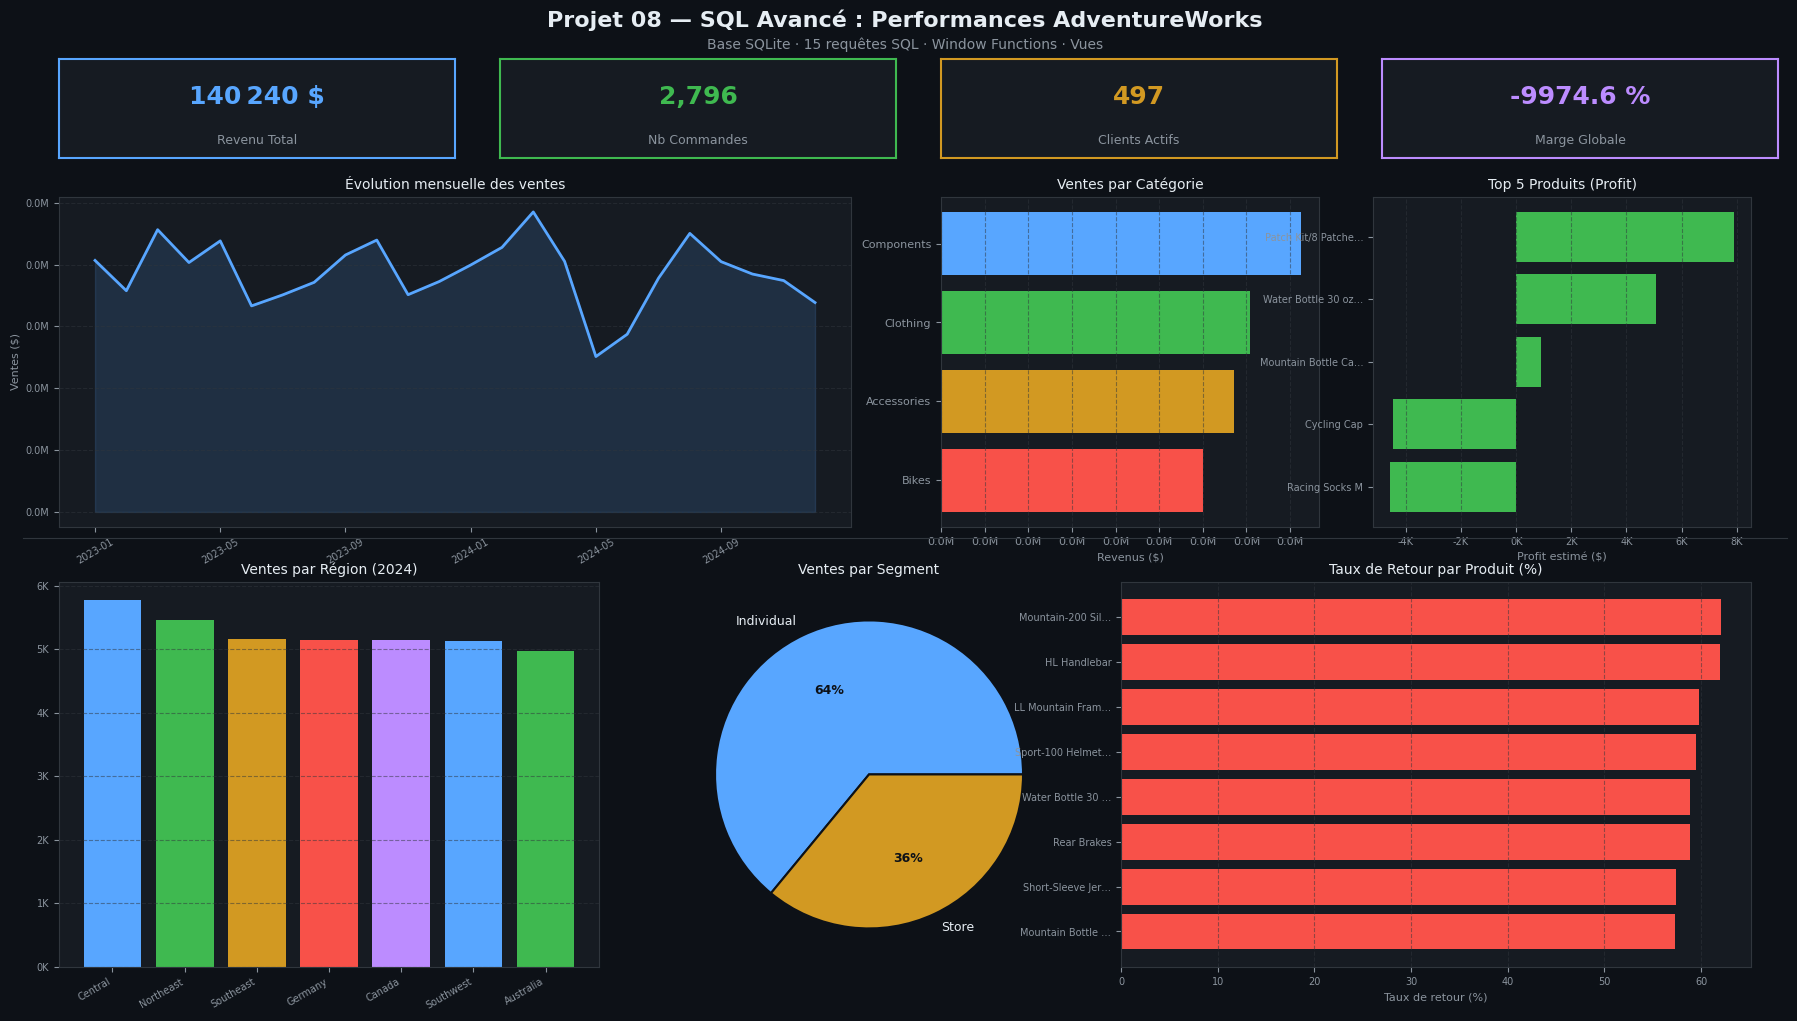

✅ Dashboard sauvegardé : ../images/00_dashboard_sql.png


In [20]:
import os
os.makedirs('../images', exist_ok=True)

# --- Données pour le dashboard ---
kpi = pd.read_sql('SELECT * FROM vue_kpi_global', conn).iloc[0]
df_cat = pd.read_sql(q3, conn)
df_reg = pd.read_sql(q1, conn).head(7)
df_top5 = pd.read_sql(q5, conn)
df_seg = pd.read_sql(q6, conn)
df_monthly = pd.read_sql('''
    SELECT strftime('%Y-%m', soh.OrderDate) AS Mois,
           ROUND(SUM(sod.LineTotal),0) AS Ventes
    FROM SalesOrderHeader soh
    JOIN SalesOrderDetail sod ON soh.SalesOrderID = sod.SalesOrderID
    WHERE strftime('%Y', soh.OrderDate) IN ('2023','2024')
    GROUP BY Mois ORDER BY Mois
''', conn)

DARK  = '#0d1117'
CARD  = '#161b22'
BORD  = '#30363d'
TEXT  = '#e6edf3'
DIM   = '#8b949e'
BLUE  = '#58a6ff'
GREEN = '#3fb950'
ORNG  = '#d29922'
RED   = '#f85149'
PURP  = '#bc8cff'
COLORS = [BLUE, GREEN, ORNG, RED, PURP]

fig = plt.figure(figsize=(18, 11))
fig.patch.set_facecolor(DARK)

# Titre
fig.text(0.5, 0.97, 'Projet 08 — SQL Avancé : Performances AdventureWorks',
         ha='center', va='top', fontsize=16, fontweight='bold', color=TEXT)
fig.text(0.5, 0.945, 'Base SQLite · 15 requêtes SQL · Window Functions · Vues',
         ha='center', va='top', fontsize=10, color=DIM)

# --- KPI TILES (4 tuiles en haut) ---
kpi_vals = [
    (f"{int(kpi['RevenuTotal']):,}".replace(',','\u202f') + ' $', 'Revenu Total',    BLUE),
    (f"{int(kpi['TotalCommandes']):,}",                            'Nb Commandes',   GREEN),
    (f"{int(kpi['TotalClients']):,}",                              'Clients Actifs', ORNG),
    (f"{kpi['MargeGlobale_Pct']:.1f} %",                          'Marge Globale',  PURP),
]
for i, (val, label, col) in enumerate(kpi_vals):
    ax = fig.add_axes([0.03 + i*0.245, 0.835, 0.22, 0.09])
    ax.set_facecolor(CARD)
    for sp in ax.spines.values(): sp.set_edgecolor(col); sp.set_linewidth(1.5)
    ax.set_xticks([]); ax.set_yticks([])
    ax.text(0.5, 0.62, val,   ha='center', va='center', fontsize=18, fontweight='bold', color=col, transform=ax.transAxes)
    ax.text(0.5, 0.18, label, ha='center', va='center', fontsize=9,  color=DIM, transform=ax.transAxes)

# --- GRAPHIQUE 1 : Évolution mensuelle ---
ax1 = fig.add_axes([0.03, 0.50, 0.44, 0.30])
ax1.set_facecolor(CARD)
ax1.plot(range(len(df_monthly)), df_monthly['Ventes'], color=BLUE, linewidth=2)
ax1.fill_between(range(len(df_monthly)), df_monthly['Ventes'], alpha=0.15, color=BLUE)
step = max(1, len(df_monthly)//6)
ax1.set_xticks(range(0, len(df_monthly), step))
ax1.set_xticklabels(df_monthly['Mois'].iloc[::step], rotation=30, fontsize=7, color=DIM)
ax1.set_title('Évolution mensuelle des ventes', color=TEXT, fontsize=10, pad=6)
ax1.set_ylabel('Ventes ($)', color=DIM, fontsize=8)
ax1.tick_params(colors=DIM, labelsize=7)
for sp in ax1.spines.values(): sp.set_edgecolor(BORD)
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda x,_: f'{x/1e6:.1f}M'))
ax1.grid(axis='y', color=BORD, linestyle='--', alpha=0.5)

# --- GRAPHIQUE 2 : Ventes par catégorie ---
ax2 = fig.add_axes([0.52, 0.50, 0.21, 0.30])
ax2.set_facecolor(CARD)
bars = ax2.barh(df_cat['CategoryName'], df_cat['VentesTotales'], color=COLORS[:len(df_cat)])
ax2.set_title('Ventes par Catégorie', color=TEXT, fontsize=10, pad=6)
ax2.tick_params(colors=DIM, labelsize=8)
for sp in ax2.spines.values(): sp.set_edgecolor(BORD)
ax2.xaxis.set_major_formatter(plt.FuncFormatter(lambda x,_: f'{x/1e6:.1f}M'))
ax2.set_xlabel('Revenus ($)', color=DIM, fontsize=8)
ax2.grid(axis='x', color=BORD, linestyle='--', alpha=0.5)
ax2.invert_yaxis()

# --- GRAPHIQUE 3 : Top 5 produits rentables ---
ax3 = fig.add_axes([0.76, 0.50, 0.21, 0.30])
ax3.set_facecolor(CARD)
names_short = [n[:18]+'…' if len(n)>18 else n for n in df_top5['ProductName']]
ax3.barh(names_short, df_top5['ProfitEstime'], color=GREEN)
ax3.set_title('Top 5 Produits (Profit)', color=TEXT, fontsize=10, pad=6)
ax3.tick_params(colors=DIM, labelsize=7)
for sp in ax3.spines.values(): sp.set_edgecolor(BORD)
ax3.xaxis.set_major_formatter(plt.FuncFormatter(lambda x,_: f'{x/1e3:.0f}K'))
ax3.set_xlabel('Profit estimé ($)', color=DIM, fontsize=8)
ax3.grid(axis='x', color=BORD, linestyle='--', alpha=0.5)
ax3.invert_yaxis()

# --- GRAPHIQUE 4 : Ventes par région ---
ax4 = fig.add_axes([0.03, 0.10, 0.30, 0.35])
ax4.set_facecolor(CARD)
bars4 = ax4.bar(df_reg['RegionName'], df_reg['VentesTotales'], color=COLORS)
ax4.set_title('Ventes par Région (2024)', color=TEXT, fontsize=10, pad=6)
ax4.tick_params(colors=DIM, labelsize=7)
ax4.set_xticklabels(df_reg['RegionName'], rotation=30, ha='right', fontsize=7)
for sp in ax4.spines.values(): sp.set_edgecolor(BORD)
ax4.yaxis.set_major_formatter(plt.FuncFormatter(lambda x,_: f'{x/1e3:.0f}K'))
ax4.grid(axis='y', color=BORD, linestyle='--', alpha=0.5)

# --- GRAPHIQUE 5 : Segment clients (pie) ---
ax5 = fig.add_axes([0.37, 0.10, 0.22, 0.35])
ax5.set_facecolor(CARD)
wedges, texts, autotexts = ax5.pie(
    df_seg['VentesTotales'], labels=df_seg['Segment'],
    autopct='%1.0f%%', colors=[BLUE, ORNG],
    textprops={'color': TEXT, 'fontsize': 9},
    wedgeprops={'linewidth': 1.5, 'edgecolor': DARK}
)
for at in autotexts: at.set_color(DARK); at.set_fontweight('bold')
ax5.set_title('Ventes par Segment', color=TEXT, fontsize=10, pad=6)

# --- GRAPHIQUE 6 : Taux de retour ---
ax6 = fig.add_axes([0.62, 0.10, 0.35, 0.35])
ax6.set_facecolor(CARD)
df14_top = df14.head(8)
names_r = [n[:16]+'…' if len(n)>16 else n for n in df14_top['ProductName']]
ax6.barh(names_r, df14_top['TauxRetour_Pct'], color=RED)
ax6.set_title('Taux de Retour par Produit (%)', color=TEXT, fontsize=10, pad=6)
ax6.tick_params(colors=DIM, labelsize=7)
for sp in ax6.spines.values(): sp.set_edgecolor(BORD)
ax6.set_xlabel('Taux de retour (%)', color=DIM, fontsize=8)
ax6.grid(axis='x', color=BORD, linestyle='--', alpha=0.5)
ax6.invert_yaxis()

# Ligne de séparation
fig.add_artist(plt.Line2D([0.01, 0.99], [0.49, 0.49], color=BORD, linewidth=0.8,
                           transform=fig.transFigure))

plt.savefig('../images/00_dashboard_sql.png', dpi=150, bbox_inches='tight',
            facecolor=DARK)
plt.show()
print('✅ Dashboard sauvegardé : ../images/00_dashboard_sql.png')

In [21]:
conn.close()
print('✅ Connexion SQLite fermée')
print('\n=== SYNTHÈSE PROJET 08 ===')
print(f'  Base de données : AdventureWorks SQLite')
print(f'  Tables créées   : 9')
print(f'  Vues SQL        : 3')
print(f'  Requêtes SQL    : 15 (jointures, agrégations, window functions, CASE WHEN, RANK, NTILE)')
print(f'  Visuels         : 6 graphiques + 4 KPI tiles')
print(f'  Dashboard       : ../images/00_dashboard_sql.png')

✅ Connexion SQLite fermée

=== SYNTHÈSE PROJET 08 ===
  Base de données : AdventureWorks SQLite
  Tables créées   : 9
  Vues SQL        : 3
  Requêtes SQL    : 15 (jointures, agrégations, window functions, CASE WHEN, RANK, NTILE)
  Visuels         : 6 graphiques + 4 KPI tiles
  Dashboard       : ../images/00_dashboard_sql.png
